# Proyek UTS — Klasifikasi Penyakit Daun Padi Menggunakan MLP dan CNN

**Mata kuliah:** Pengantar Algoritma Deep Learning  
**Jalur:** A — klasifikasi citra  
**Dataset:** [Project-AgML/rice_leaf_disease_classification_india](https://huggingface.co/datasets/Project-AgML/rice_leaf_disease_classification_india)  
**Model yang dibandingkan:** **MLP dan CNN sederhana** (hanya dua model)

### Cara menggunakan notebook ini
1. Jalankan sel **dari atas ke bawah**, satu per satu, dengan tombol ▶ di sebelah kiri sel.
2. Saat latihan model, sebaiknya aktifkan GPU di **Runtime → Change runtime type → T4 GPU** jika tersedia. CPU tetap bisa digunakan.
3. **Jangan melompati sel:** variabel dari sel sebelumnya diperlukan oleh sel berikutnya.
4. Angka hasil dan grafik akan muncul **setelah kode dijalankan**; tidak ada akurasi yang dikarang.

### Sesuai persyaratan UTS pada panduan dosen
- Dataset gambar minimal **2.000**, lisensi jelas; dipisah menjadi **train/validation/test**.
- Membangun dan melatih **MLP + CNN sederhana** dengan TensorFlow/Keras.
- Menjelaskan arsitektur, loss, optimizer, hyperparameter; mengamati proses forward/backpropagation.
- Menghasilkan **grafik accuracy/loss, confusion matrix, tabel perbandingan dan contoh kesalahan**.
- Menyimpan hasil yang dapat digunakan nanti untuk **laporan UTS maksimal 8 halaman**.

**Belum dikerjakan (UAS):** transfer learning, ResNet/EfficientNet, Grad-CAM, hyperparameter search besar, dan aplikasi web.

## 1. Instal library dan siapkan lingkungan

**Tujuan:** mengaktifkan alat yang diperlukan. `datasets` digunakan untuk memuat foto dari Hugging Face; TensorFlow/Keras untuk model; NumPy untuk data; Matplotlib untuk grafik; scikit-learn untuk pembagian dan evaluasi.

**Hasil yang diharapkan:** kode selesai tanpa error. Baris instalasi hanya perlu dilakukan satu kali setiap sesi Colab baru.

In [ ]:
%pip -q install datasets

In [ ]:
import os
import json
import hashlib
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Folder untuk menyimpan model, tabel, dan gambar hasil.
ROOT = Path('/content/UTS_Padi') if Path('/content').exists() else Path.cwd() / 'UTS_Padi'
for folder in ['data', 'notebooks', 'src', 'models', 'reports']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print('TensorFlow:', tf.__version__)
print('GPU tersedia:', tf.config.list_physical_devices('GPU'))
print('Folder hasil:', ROOT)

TensorFlow: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Folder hasil: /content/UTS_Padi


## 2. Memuat dataset

**Tujuan:** mengambil foto daun padi beserta label penyakitnya. `load_dataset(...)` **belum melatih model**—baru memuat data. Sumber dataset menyatakan total awal **5.932 gambar, 4 kelas, lisensi CC BY 4.0**. Kita tetap memeriksa angka aslinya melalui kode.

**Penting:** dataset aslinya memiliki split bernama `train` saja, sehingga nanti **kita buat sendiri** split validation dan test.

In [ ]:
DATASET_ID = 'Project-AgML/rice_leaf_disease_classification_india'
ds = load_dataset(DATASET_ID)
raw = ds['train']

assert 'image' in raw.column_names, 'Kolom image tidak ditemukan.'
assert 'label' in raw.column_names, 'Kolom label tidak ditemukan.'

class_names = raw.features['label'].names
NUM_CLASSES = len(class_names)
print(ds)
print('Jumlah foto asli:', len(raw))
print('Jumlah kelas:', NUM_CLASSES)
print('Nama kelas:', class_names)
assert len(raw) >= 2000, 'Data belum memenuhi syarat minimal 2.000 gambar.'
assert NUM_CLASSES >= 2, 'Dataset perlu lebih dari satu kategori.'

README.md:   0%|          | 0.00/1.49k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  208MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5932 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5932
    })
})
Jumlah foto asli: 5932
Jumlah kelas: 4
Nama kelas: ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro']


## 3. Mengenal empat kelas penyakit dan melihat contoh gambar

**Tujuan:** mengetahui keseimbangan jumlah gambar per penyakit dan memastikan fotonya dapat dibaca. Dataset ini hanya memiliki empat kategori **penyakit**, **tidak ada kategori daun sehat**.

**Hasil:** tabel jumlah kelas, diagram batang, dan empat contoh foto.

,Kelas,Jumlah gambar
0,Bacterialblight,1584
1,Blast,1440
2,Brownspot,1600
3,Tungro,1308


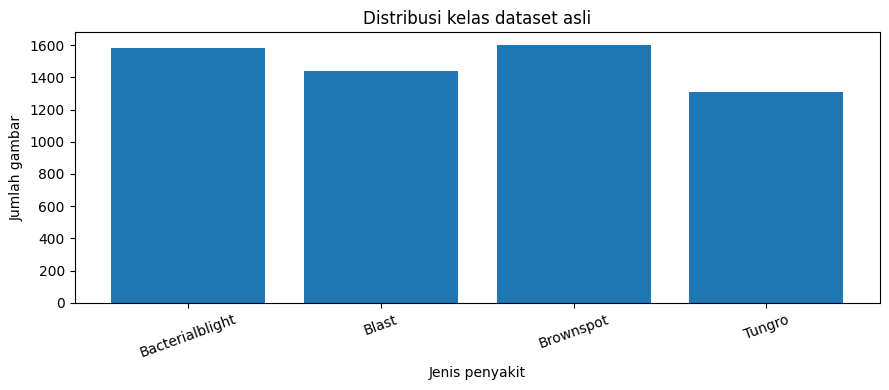

In [ ]:
raw_labels = np.asarray(raw['label'], dtype=np.int32)
count_df = pd.DataFrame({
    'Kelas': class_names,
    'Jumlah gambar': [int(np.sum(raw_labels == i)) for i in range(NUM_CLASSES)]
})
display(count_df)

plt.figure(figsize=(9, 4))
plt.bar(count_df['Kelas'], count_df['Jumlah gambar'])
plt.title('Distribusi kelas dataset asli')
plt.xlabel('Jenis penyakit')
plt.ylabel('Jumlah gambar')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(ROOT / 'reports' / 'distribusi_kelas_asli.png', dpi=150)
plt.show()

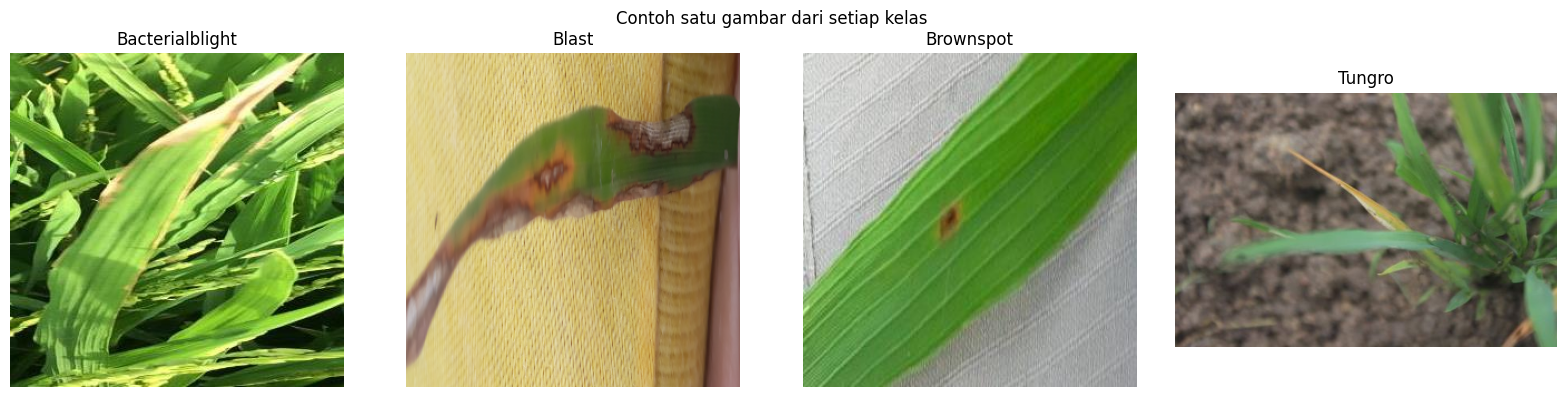

In [ ]:
fig, axs = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 4))
axs = np.atleast_1d(axs)
for i, ax in enumerate(axs):
    indeks = int(np.where(raw_labels == i)[0][0])
    ax.imshow(raw[indeks]['image'].convert('RGB'))
    ax.set_title(class_names[i])
    ax.axis('off')
plt.suptitle('Contoh satu gambar dari setiap kelas')
plt.tight_layout()
plt.savefig(ROOT / 'reports' / 'contoh_empat_kelas.png', dpi=150)
plt.show()

## 4. Preprocessing: siapkan foto dengan ukuran yang sama

**Tujuan:** semua foto diubah menjadi **RGB 96 × 96 piksel**, sehingga dapat dibaca oleh MLP dan CNN dengan masukan yang sama. Nilai warna masih berupa bilangan bulat 0–255 di memori (lebih hemat RAM); normalisasi 0–1 dilakukan **per batch** saat pelatihan.

Kita juga memeriksa **duplikat persis setelah gambar di-resize** dan menghapus salinannya, agar gambar identik tidak muncul pada training sekaligus testing. Jika ada gambar identik dengan dua label berbeda, notebook akan melaporkannya. Pemeriksaan ini **tidak menjamin** tidak adanya foto hampir sama (*near-duplicate*).

**Hasil:** `X_all` (kumpulan gambar), `y_all` (label), dan ringkasan jumlah gambar yang lolos.

In [ ]:
IMG_SIZE = 96  # ukuran sama untuk MLP dan CNN
images = []
labels = []
seen = {}  # hash gambar -> label pertama
duplicate_count = 0
label_conflicts = 0

for sample in tqdm(raw, total=len(raw), desc='Mengecilkan dan memeriksa gambar'):
    img = sample['image'].convert('RGB')
    img = img.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
    arr = np.asarray(img, dtype=np.uint8)
    label = int(sample['label'])
    fingerprint = hashlib.sha256(arr.tobytes()).hexdigest()

    if fingerprint in seen:
        duplicate_count += 1
        if seen[fingerprint] != label:
            label_conflicts += 1
        continue

    seen[fingerprint] = label
    images.append(arr)
    labels.append(label)

X_all = np.stack(images).astype(np.uint8)
y_all = np.asarray(labels, dtype=np.int32)
del images, labels, seen

print('Gambar asli      :', len(raw))
print('Duplikat dibuang :', duplicate_count)
print('Konflik label    :', label_conflicts)
print('Gambar digunakan :', len(X_all))
print('Ukuran satu foto :', X_all.shape[1:])
print('Format data      :', X_all.dtype)
assert len(X_all) >= 2000, 'Setelah pembersihan, jumlah gambar kurang dari 2.000.'
assert len(np.unique(y_all)) == NUM_CLASSES, 'Ada kelas yang hilang setelah pembersihan.'

Mengecilkan dan memeriksa gambar:   0%|          | 0/5932 [00:00<?, ?it/s]

Gambar asli      : 5932
Duplikat dibuang : 1180
Konflik label    : 0
Gambar digunakan : 4752
Ukuran satu foto : (96, 96, 3)
Format data      : uint8


## 5. Membagi data menjadi train, validation, dan test

**Tujuan:** memastikan evaluasi adil. Gunakan **70% training**, **15% validation**, **15% testing**. `stratify` mempertahankan perbandingan empat kelas penyakit pada tiap bagian; `random_state=42` membuat pembagian dapat diulang.

> Analoginya: **training** untuk belajar; **validation** untuk memantau proses dan memilih bobot terbaik; **testing** untuk ujian akhir. Data testing **tidak** boleh digunakan untuk menyesuaikan model.

**Hasil:** enam variabel (`X_train`, `X_val`, `X_test`, dan tiga `y_...`), serta tabel jumlah per kelas.

In [ ]:
semua_indeks = np.arange(len(y_all))
idx_train, idx_sisa = train_test_split(
    semua_indeks, test_size=0.30, random_state=SEED, stratify=y_all
)
idx_val, idx_test = train_test_split(
    idx_sisa, test_size=0.50, random_state=SEED,
    stratify=y_all[idx_sisa]
)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]

# Hilangkan salinan yang sudah tidak dibutuhkan agar RAM lebih ringan.
del X_all
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0

print('Training  :', len(X_train), 'gambar')
print('Validation:', len(X_val), 'gambar')
print('Testing   :', len(X_test), 'gambar')

pembagian_df = pd.DataFrame({
    'Kelas': class_names,
    'Training': [int(np.sum(y_train == i)) for i in range(NUM_CLASSES)],
    'Validation': [int(np.sum(y_val == i)) for i in range(NUM_CLASSES)],
    'Testing': [int(np.sum(y_test == i)) for i in range(NUM_CLASSES)]
})
display(pembagian_df)
pembagian_df.to_csv(ROOT / 'reports' / 'pembagian_dataset.csv', index=False)

Training  : 3326 gambar
Validation: 713 gambar
Testing   : 713 gambar


,Kelas,Training,Validation,Testing
0,Bacterialblight,899,192,193
1,Blast,672,144,144
2,Brownspot,840,180,180
3,Tungro,915,197,196


## 6. Membuat pipeline gambar untuk training

**Tujuan:** mengirim gambar dalam paket kecil (*batch*) agar tidak memberatkan memori. Di sini nilai piksel dinormalisasi dari rentang **0–255 menjadi 0–1** dengan dibagi 255.

**Penting:** hanya data **training** yang diacak (`shuffle`). Validation dan testing tidak diacak supaya urutan prediksinya cocok dengan label asli saat evaluasi.

In [ ]:
BATCH_SIZE = 32
EPOCHS = 15               # batas atas; early stopping dapat berhenti lebih awal
LEARNING_RATE = 0.001
AUTOTUNE = tf.data.AUTOTUNE

def buat_pipeline(X, y, acak=False):
    data = tf.data.Dataset.from_tensor_slices((X, y))
    if acak:
        data = data.shuffle(buffer_size=min(len(X), 1000), seed=SEED)
    data = data.batch(BATCH_SIZE)
    data = data.map(
        lambda x, label: (tf.cast(x, tf.float32) / 255.0, label),
        num_parallel_calls=AUTOTUNE
    )
    return data.prefetch(AUTOTUNE)

train_tf = buat_pipeline(X_train, y_train, acak=True)
val_tf = buat_pipeline(X_val, y_val)
test_tf = buat_pipeline(X_test, y_test)

print('Ukuran foto:', IMG_SIZE, 'x', IMG_SIZE)
print('Batch size:', BATCH_SIZE)
print('Maksimum epoch:', EPOCHS)
print('Learning rate:', LEARNING_RATE)

Ukuran foto: 96 x 96
Batch size: 32
Maksimum epoch: 15
Learning rate: 0.001


## 7. Membuat model pertama: MLP (baseline)

**Tujuan:** membuat model pembanding yang menerima piksel gambar sebagai deretan angka.

- `Flatten`: mengubah gambar 96×96×3 menjadi satu deretan angka.
- `Dense(128)` dan `Dense(64)`: lapisan neuron yang mempelajari hubungan piksel dan label.
- `Dropout(0.3)`: secara acak menonaktifkan 30% unit pada saat training sebagai regularisasi.
- `Dense(NUM_CLASSES, softmax)`: memberikan peluang untuk masing-masing penyakit.

Model menggunakan **Sparse Categorical Crossentropy** sebagai *loss* karena label berupa angka kelas, dan **Adam** sebagai optimizer untuk memperbarui parameter.

In [ ]:
def buat_mlp():
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='MLP_Baseline')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

mlp = buat_mlp()
mlp.summary()

Model: "MLP_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 27648)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,539,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,547,588 (13.53 MB)

 Trainable params: 3,547,588 (13.53 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Membuat model kedua: CNN sederhana

**Tujuan:** membangun model yang mempertahankan susunan piksel dan mempelajari pola visual, misalnya bercak dan tekstur.

- `Conv2D`: mempelajari ciri pada area kecil gambar.
- `MaxPooling2D`: merangkum ciri sambil mengecilkan ukuran representasi.
- `Flatten` dan `Dense`: menggabungkan ciri untuk memprediksi penyakit.

CNN menggunakan ukuran masukan, data, optimizer, dan batas epoch yang **sama** dengan MLP supaya perbandingannya lebih masuk akal.

In [ ]:
def buat_cnn():
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ], name='CNN_Sederhana')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn = buat_cnn()
cnn.summary()

Model: "CNN_Sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       589,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 613,732 (2.34 MB)

 Trainable params: 613,732 (2.34 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Simpan diagram arsitektur kedua model

**Tujuan:** menghasilkan **diagram arsitektur** yang nanti dapat digunakan di bagian Metodologi laporan. Nama jenis layer, ukuran keluaran, dan jumlah parameter tersedia pula lewat `model.summary()`.

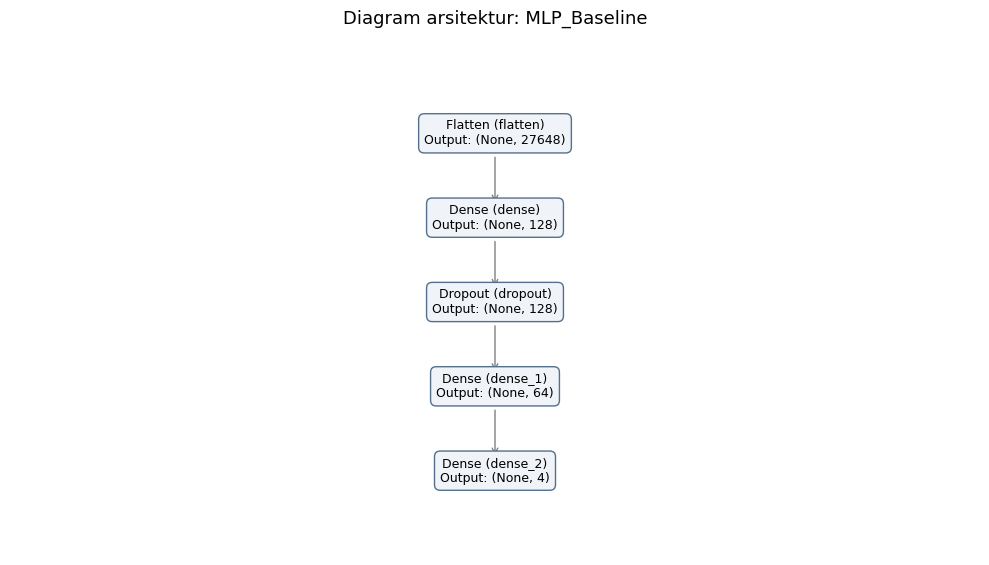

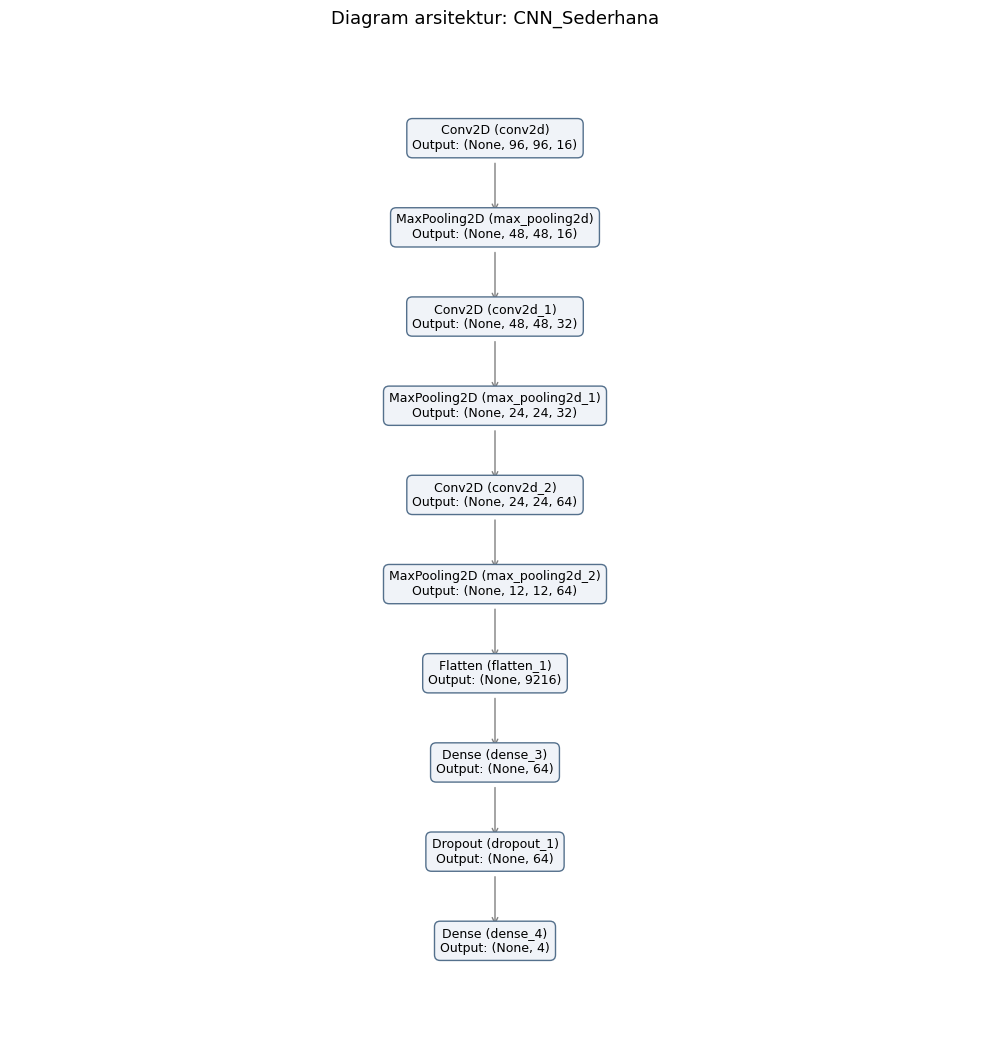

In [ ]:
def gambar_arsitektur(model, nama_file):
    daftar_layer = model.layers
    tinggi = max(5, 0.95 * len(daftar_layer) + 1)
    fig, ax = plt.subplots(figsize=(10, tinggi))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, len(daftar_layer) + 1)
    ax.axis('off')
    ax.set_title('Diagram arsitektur: ' + model.name, fontsize=13, pad=18)
    for i, layer in enumerate(daftar_layer):
        y = len(daftar_layer) - i
        try:
            bentuk = str(tuple(layer.output.shape))
        except Exception:
            bentuk = 'Lihat model.summary()'
        teks = f'{layer.__class__.__name__} ({layer.name})\nOutput: {bentuk}'
        ax.text(5, y, teks, ha='center', va='center', fontsize=9,
                bbox={'boxstyle': 'round,pad=0.45', 'facecolor': '#f0f3f8', 'edgecolor': '#54708c'})
        if i < len(daftar_layer) - 1:
            ax.annotate('', xy=(5, y-0.85), xytext=(5, y-0.25),
                        arrowprops={'arrowstyle': '->', 'color': 'gray'})
    fig.tight_layout()
    fig.savefig(ROOT / 'reports' / nama_file, dpi=180, bbox_inches='tight')
    plt.show()

gambar_arsitektur(mlp, 'diagram_arsitektur_MLP.png')
gambar_arsitektur(cnn, 'diagram_arsitektur_CNN.png')

## 10. Memahami forward propagation, backpropagation, dan optimizer

Dalam setiap batch saat `fit` berjalan:

1. **Forward propagation:** foto melewati layer hingga menghasilkan prediksi.
2. **Loss:** prediksi dibandingkan dengan label yang benar.
3. **Backpropagation:** TensorFlow menghitung gradien kesalahan untuk parameter model.
4. **Adam (gradient-based optimizer):** parameter diperbarui menggunakan gradien tersebut.

Sel berikut **hanya memperlihatkan gradien pada satu batch**, tanpa mengubah parameter model. Proses pembaruan parameter sebenarnya dilakukan otomatis saat `fit` pada langkah selanjutnya.

In [ ]:
contoh_X, contoh_y = next(iter(train_tf))
with tf.GradientTape() as tape:
    prediksi = mlp(contoh_X, training=True)  # forward propagation
    nilai_loss = tf.keras.losses.sparse_categorical_crossentropy(contoh_y, prediksi)
    nilai_loss = tf.reduce_mean(nilai_loss)

gradien = tape.gradient(nilai_loss, mlp.trainable_variables)  # backpropagation
jumlah_gradien = sum(g is not None for g in gradien)
print('Contoh loss satu batch:', round(float(nilai_loss.numpy()), 4))
print('Jumlah kelompok parameter dengan gradien:', jumlah_gradien)
print('Adam akan memakai gradien seperti ini saat pelatihan.')

Contoh loss satu batch: 1.6292
Jumlah kelompok parameter dengan gradien: 6
Adam akan memakai gradien seperti ini saat pelatihan.


## 11. Training model MLP

**Tujuan:** model belajar menggunakan data training; hasil di validation dipantau tiap epoch. `EarlyStopping` berhenti jika validation loss tidak membaik selama 3 epoch berturut-turut, lalu mengembalikan bobot terbaik.

**Hasil yang diharapkan:** tabel per epoch berisi `accuracy`, `loss`, `val_accuracy`, dan `val_loss`. Akurasinya **baru diketahui setelah dijalankan**.

In [ ]:
def callback_training():
    return [tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True
    )]

riwayat_mlp = mlp.fit(
    train_tf,
    validation_data=val_tf,
    epochs=EPOCHS,
    callbacks=callback_training(),
    verbose=1
)
mlp.save(ROOT / 'models' / 'model_MLP.keras')
print('Model MLP tersimpan.')

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.3608 - loss: 2.1971 - val_accuracy: 0.5021 - val_loss: 1.1927
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4369 - loss: 1.2087 - val_accuracy: 0.4712 - val_loss: 1.1344
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4429 - loss: 1.1878 - val_accuracy: 0.4656 - val_loss: 1.2127
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4116 - loss: 1.2376 - val_accuracy: 0.4797 - val_loss: 1.1583
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4351 - loss: 1.1854 - val_accuracy: 0.5119 - val_loss: 1.1056
Epoch 6/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4230 - loss: 1.2140 - val_accuracy: 0.4755 - val_loss: 1.1355
Epoch 7/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4348 - loss: 1.1885 - val_accuracy: 0.5035 - val_loss: 1.1028
Epoch 8/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4336 - loss: 1.1987 - val_accuracy: 0

## 12. Training model CNN

**Tujuan:** melatih CNN pada **foto training yang sama** dengan MLP. Jangan mengubah pembagian data sebelum CNN dilatih.

**Hasil yang diharapkan:** tabel pelatihan CNN dan file model CNN.

In [ ]:
riwayat_cnn = cnn.fit(
    train_tf,
    validation_data=val_tf,
    epochs=EPOCHS,
    callbacks=callback_training(),
    verbose=1
)
cnn.save(ROOT / 'models' / 'model_CNN.keras')
print('Model CNN tersimpan.')

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.4892 - loss: 1.1481 - val_accuracy: 0.6704 - val_loss: 0.8431
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6960 - loss: 0.7724 - val_accuracy: 0.7980 - val_loss: 0.5564
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7793 - loss: 0.5771 - val_accuracy: 0.8163 - val_loss: 0.4572
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8151 - loss: 0.4782 - val_accuracy: 0.8836 - val_loss: 0.3233
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8626 - loss: 0.3626 - val_accuracy: 0.8738 - val_loss: 0.3085
Epoch 6/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8656 - loss: 0.3365 - val_accuracy: 0.8962 - val_loss: 0.2581
Epoch 7/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8882 - loss: 0.2759 - val_accuracy: 0.9299 - val_loss: 0.2204
Epoch 8/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8984 - loss: 0.2458 - val_accurac

## 13. Grafik perubahan accuracy dan loss selama training

**Tujuan:** memperlihatkan apakah model semakin baik saat belajar dan apakah terjadi gejala *overfitting* (training bagus, validation jauh lebih buruk).

**Hasil:** dua file grafik untuk laporan, masing-masing accuracy dan loss. Jumlah epoch tiap model bisa berbeda karena early stopping.

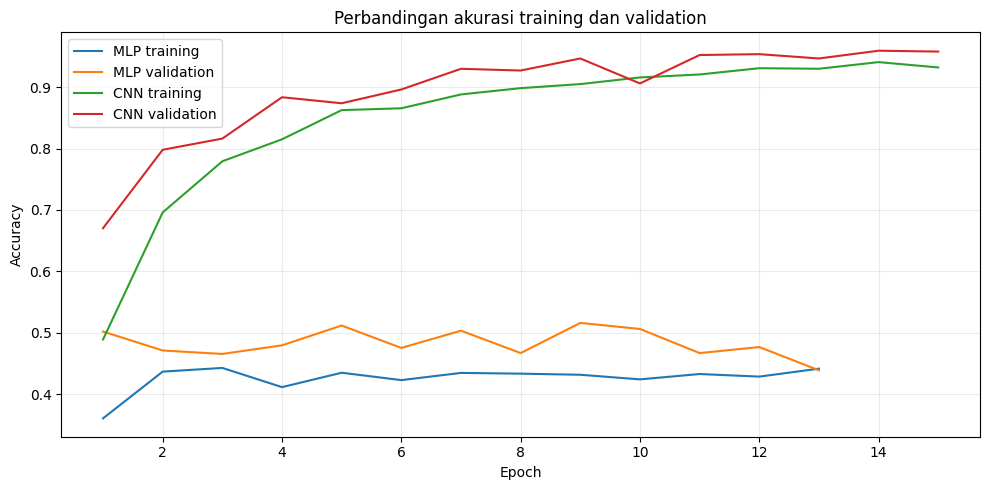

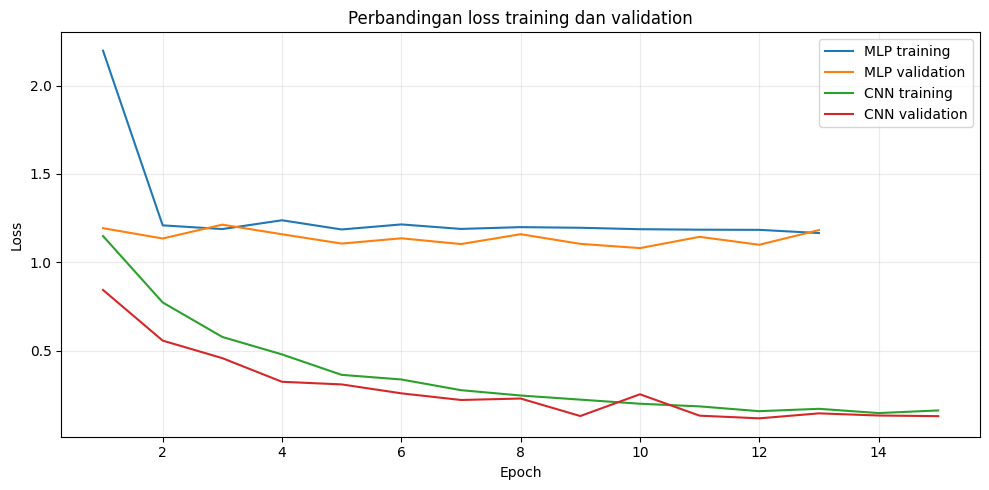

In [ ]:
def gambar_metrik(riwayat1, riwayat2, metrik, judul, filename):
    plt.figure(figsize=(10, 5))
    for nama, riwayat in [('MLP', riwayat1), ('CNN', riwayat2)]:
        for jenis, label in [(metrik, 'training'), ('val_' + metrik, 'validation')]:
            nilai = riwayat.history[jenis]
            plt.plot(range(1, len(nilai)+1), nilai, label=f'{nama} {label}')
    plt.title(judul)
    plt.xlabel('Epoch')
    plt.ylabel(metrik.capitalize())
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(ROOT / 'reports' / filename, dpi=160)
    plt.show()

gambar_metrik(riwayat_mlp, riwayat_cnn, 'accuracy',
              'Perbandingan akurasi training dan validation', 'grafik_akurasi.png')
gambar_metrik(riwayat_mlp, riwayat_cnn, 'loss',
              'Perbandingan loss training dan validation', 'grafik_loss.png')

## 14. Evaluasi final pada TESTING (data yang belum pernah dipakai belajar)

**Tujuan:** menghitung nilai **accuracy, loss, precision, recall, dan F1 macro** dari MLP dan CNN menggunakan testing yang **sama**. Bagian ini baru boleh dijalankan setelah kedua training selesai.

**Hasil:** tabel perbandingan model. Data testing tidak digunakan untuk melatih maupun memutuskan kapan training berhenti.

In [ ]:
loss_mlp, acc_mlp = mlp.evaluate(test_tf, verbose=0)
loss_cnn, acc_cnn = cnn.evaluate(test_tf, verbose=0)

prob_mlp = mlp.predict(test_tf, verbose=0)
prob_cnn = cnn.predict(test_tf, verbose=0)
pred_mlp = np.argmax(prob_mlp, axis=1)
pred_cnn = np.argmax(prob_cnn, axis=1)

baris_hasil = []
for nama, loss, pred in [('MLP', loss_mlp, pred_mlp), ('CNN', loss_cnn, pred_cnn)]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, average='macro', zero_division=0
    )
    baris_hasil.append({
        'Model': nama,
        'Accuracy_testing': float(accuracy_score(y_test, pred)),
        'Loss_testing': float(loss),
        'Precision_macro': float(precision),
        'Recall_macro': float(recall),
        'F1_macro': float(f1),
    })

hasil_df = pd.DataFrame(baris_hasil)
display(hasil_df.round(4))
hasil_df.to_csv(ROOT / 'reports' / 'perbandingan_MLP_CNN.csv', index=False)
print('Laporan MLP:')
print(classification_report(y_test, pred_mlp, labels=list(range(NUM_CLASSES)),
                            target_names=class_names, zero_division=0))
print('Laporan CNN:')
print(classification_report(y_test, pred_cnn, labels=list(range(NUM_CLASSES)),
                            target_names=class_names, zero_division=0))

,Model,Accuracy_testing,Loss_testing,Precision_macro,Recall_macro,F1_macro
0,MLP,0.5245,1.0808,0.6097,0.4998,0.4353
1,CNN,0.9523,0.1212,0.9498,0.9507,0.9501


Laporan MLP:
                 precision    recall  f1-score   support

Bacterialblight       0.65      0.12      0.21       193
          Blast       0.57      0.08      0.15       144
      Brownspot       0.82      0.82      0.82       180
         Tungro       0.40      0.97      0.57       196

       accuracy                           0.52       713
      macro avg       0.61      0.50      0.44       713
   weighted avg       0.61      0.52      0.45       713

Laporan CNN:
                 precision    recall  f1-score   support

Bacterialblight       0.97      0.94      0.96       193
          Blast       0.91      0.93      0.92       144
      Brownspot       0.94      0.94      0.94       180
         Tungro       0.97      0.99      0.98       196

       accuracy                           0.95       713
      macro avg       0.95      0.95      0.95       713
   weighted avg       0.95      0.95      0.95       713



## 15. Membuat confusion matrix kedua model

**Tujuan:** melihat *jenis penyakit mana yang sering salah ditebak*. Nilai pada **diagonal** berarti prediksi benar. Nilai di luar diagonal menunjukkan kesalahan antar-kelas.

**Hasil:** dua gambar confusion matrix untuk bagian Eksperimen & Hasil laporan.

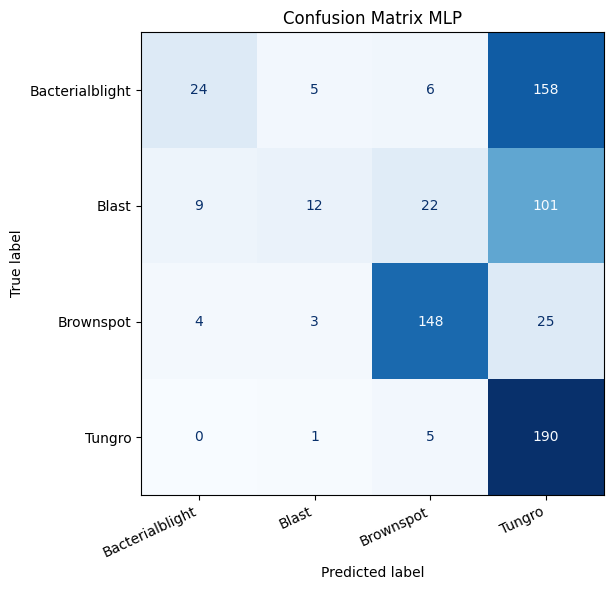

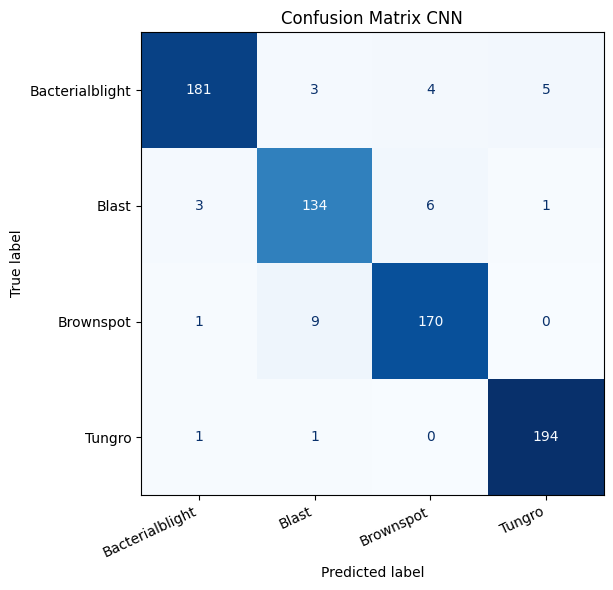

In [ ]:
def tampil_confusion_matrix(y_benar, y_prediksi, nama):
    cm = confusion_matrix(y_benar, y_prediksi, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(8, 6))
    display_cm = ConfusionMatrixDisplay(cm, display_labels=class_names)
    display_cm.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(f'Confusion Matrix {nama}')
    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    plt.savefig(ROOT / 'reports' / f'confusion_matrix_{nama}.png', dpi=160)
    plt.show()
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
        ROOT / 'reports' / f'confusion_matrix_{nama}.csv'
    )

tampil_confusion_matrix(y_test, pred_mlp, 'MLP')
tampil_confusion_matrix(y_test, pred_cnn, 'CNN')

## 16. Analisis kesalahan: contoh foto yang salah diprediksi

**Tujuan:** tidak berhenti pada angka accuracy saja. Kita lihat hingga lima foto testing yang salah diklasifikasikan CNN, lengkap dengan label asli dan prediksi. Ini dapat membantu menjelaskan keterbatasan model pada pembahasan UTS.

**Hasil:** gambar contoh kesalahan dan file CSV berisi prediksi semua foto testing. Jika tidak ada kesalahan, akan muncul pemberitahuan.

Jumlah kesalahan CNN pada test: 34 dari 713


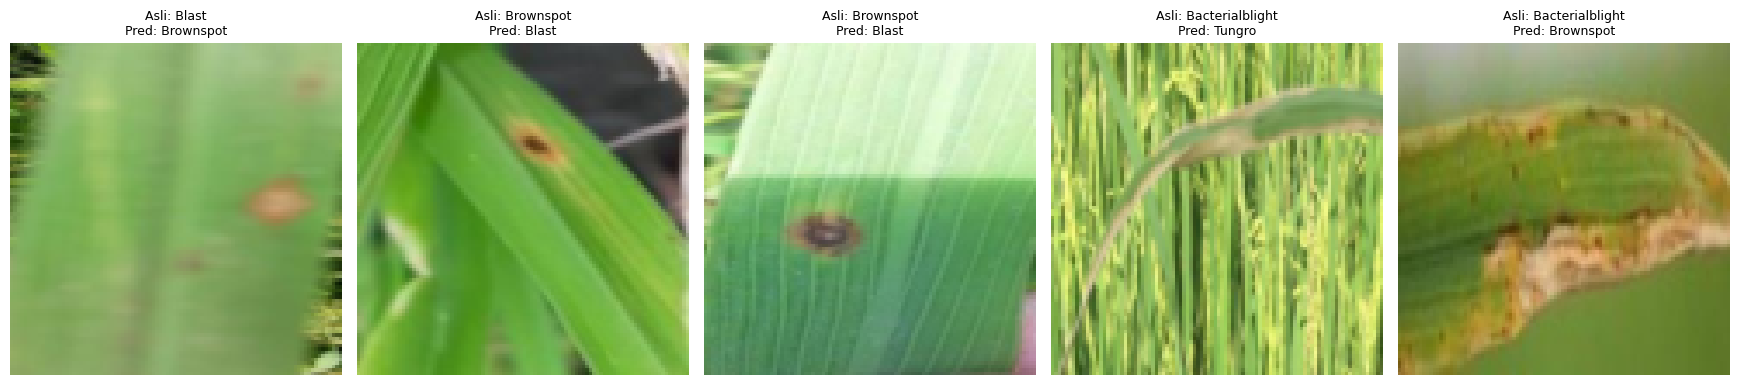

In [ ]:
prediksi_df = pd.DataFrame({
    'indeks_test': np.arange(len(y_test)),
    'label_asli': [class_names[int(i)] for i in y_test],
    'prediksi_MLP': [class_names[int(i)] for i in pred_mlp],
    'prediksi_CNN': [class_names[int(i)] for i in pred_cnn],
    'benar_MLP': pred_mlp == y_test,
    'benar_CNN': pred_cnn == y_test
})
prediksi_df.to_csv(ROOT / 'reports' / 'hasil_prediksi_testing.csv', index=False)

salah = np.where(pred_cnn != y_test)[0]
print('Jumlah kesalahan CNN pada test:', len(salah), 'dari', len(y_test))
if len(salah) > 0:
    tampil = salah[:min(5, len(salah))]
    fig, axs = plt.subplots(1, len(tampil), figsize=(3.5 * len(tampil), 4))
    axs = np.atleast_1d(axs)
    for ax, idx in zip(axs, tampil):
        ax.imshow(X_test[idx])
        ax.set_title(f'Asli: {class_names[int(y_test[idx])]}\nPred: {class_names[int(pred_cnn[idx])]}', fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(ROOT / 'reports' / 'contoh_kesalahan_CNN.png', dpi=160)
    plt.show()
else:
    print('Tidak ada prediksi CNN yang salah pada data testing.')

## 17. Kesimpulan eksperimen secara otomatis (berdasarkan hasil nyata)

**Tujuan:** membantu membaca perbandingan. Notebook tidak mengasumsikan CNN lebih baik; kesimpulan diambil dari hasil testing yang muncul setelah training.

In [ ]:
a_mlp = float(hasil_df.loc[hasil_df.Model == 'MLP', 'Accuracy_testing'].iloc[0])
a_cnn = float(hasil_df.loc[hasil_df.Model == 'CNN', 'Accuracy_testing'].iloc[0])

print(f'Akurasi testing MLP : {a_mlp:.2%}')
print(f'Akurasi testing CNN : {a_cnn:.2%}')
if a_cnn > a_mlp:
    print('Berdasarkan accuracy testing, CNN lebih baik pada percobaan ini.')
elif a_mlp > a_cnn:
    print('Berdasarkan accuracy testing, MLP lebih baik pada percobaan ini.')
else:
    print('Akurasi kedua model sama pada percobaan ini.')

print('Catatan: hasil ini hanya berlaku pada dataset, pembagian, dan setelan eksperimen ini.')

Akurasi testing MLP : 52.45%
Akurasi testing CNN : 95.23%
Berdasarkan accuracy testing, CNN lebih baik pada percobaan ini.
Catatan: hasil ini hanya berlaku pada dataset, pembagian, dan setelan eksperimen ini.


## 18. Simpan konfigurasi dan seluruh hasil eksperimen

**Tujuan:** agar pekerjaan bisa ditelusuri dan dilampirkan ke repositori serta laporan. Folder `/content/UTS_Padi` berisi `models/` dan `reports/` setelah training.

**Cara mengambil hasil:** jalankan sel ini, kemudian pada sidebar **Files** Colab unduh `/content/UTS_Padi_Hasil.zip`. Simpan juga notebook `.ipynb` melalui menu **File → Download → Download .ipynb**. Jangan hanya mengunduh ZIP tanpa notebook.

In [ ]:
import shutil

konfigurasi = {
    'dataset': DATASET_ID,
    'dataset_license': 'CC BY 4.0 (tercantum pada halaman dataset)',
    'kelas': class_names,
    'jumlah_asli': len(raw),
    'duplikat_dibuang': duplicate_count,
    'konflik_label_duplikat': label_conflicts,
    'jumlah_bersih': len(y_all),
    'jumlah_training': len(y_train),
    'jumlah_validation': len(y_val),
    'jumlah_testing': len(y_test),
    'image_size': [IMG_SIZE, IMG_SIZE, 3],
    'batch_size': BATCH_SIZE,
    'maksimal_epoch': EPOCHS,
    'epoch_MLP_berjalan': len(riwayat_mlp.history['loss']),
    'epoch_CNN_berjalan': len(riwayat_cnn.history['loss']),
    'learning_rate': LEARNING_RATE,
    'seed': SEED,
    'optimizer': 'Adam',
    'loss': 'sparse_categorical_crossentropy',
    'normalisasi': 'pixel / 255.0',
    'catatan': 'Hasil model hanya untuk klasifikasi dataset; bukan diagnosis agronomi lapangan.'
}
with open(ROOT / 'reports' / 'konfigurasi_eksperimen.json', 'w', encoding='utf-8') as f:
    json.dump(konfigurasi, f, ensure_ascii=False, indent=2)

arsip = shutil.make_archive(str(ROOT.parent / 'UTS_Padi_Hasil'), 'zip', root_dir=ROOT)
print('File hasil tersedia:', arsip)
print('Isi folder reports:')
for p in sorted((ROOT / 'reports').iterdir()):
    print('-', p.name)
print('\nJangan lupa unduh notebook .ipynb dari menu File Colab.')

File hasil tersedia: /content/UTS_Padi_Hasil.zip
Isi folder reports:
- confusion_matrix_CNN.csv
- confusion_matrix_CNN.png
- confusion_matrix_MLP.csv
- confusion_matrix_MLP.png
- contoh_empat_kelas.png
- contoh_kesalahan_CNN.png
- diagram_arsitektur_CNN.png
- diagram_arsitektur_MLP.png
- distribusi_kelas_asli.png
- grafik_akurasi.png
- grafik_loss.png
- hasil_prediksi_testing.csv
- konfigurasi_eksperimen.json
- pembagian_dataset.csv
- perbandingan_MLP_CNN.csv

Jangan lupa unduh notebook .ipynb dari menu File Colab.


## 19. Checklist setelah menjalankan seluruh notebook

Jika semua sel berhasil:

- [ ] Dataset terbaca, jumlah gambar dan kelas tampil.
- [ ] Gambar telah di-resize, duplikat identik diperiksa, dan split train/validation/test dibuat.
- [ ] MLP dan CNN **keduanya** berhasil dilatih.
- [ ] Ada grafik training/validation accuracy dan loss.
- [ ] Ada confusion matrix MLP dan CNN.
- [ ] Ada tabel perbandingan kedua model pada **data testing**.
- [ ] Ada contoh prediksi salah serta catatan keterbatasan.
- [ ] Notebook `.ipynb`, arsip hasil, dan model telah disimpan.

**Untuk pengumpulan UTS selanjutnya:** masukkan notebook ini ke `notebooks/`, hasil ke `models/` dan `reports/`, tulis `README.md`, unggah repositori ke GitHub/GitLab. Laporan dan tiga referensi ilmiah akan kita buat **sesudah hasil pelatihan nyata diperoleh**, sesuai urutan yang diminta.

**Catatan metodologi:** stratifikasi dan penghapusan duplikat identik mengurangi kebocoran data, tetapi foto yang sangat mirip, subjek sama, atau kondisi pengambilan sama masih mungkin membuat akurasi terlalu optimistis. Hal ini harus disebutkan sebagai keterbatasan jika diketahui.